# Seaborn 

In [1]:
# Def: Seaborn is a high level visualization library.
# seaborn is designed over the matplotlib.
# seaborn is used for complex charts. mainly used for statistical charts like KDE plot, pair plot.
# Seaborn library have inbuilt datasets.

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

# Built in dataset

In [3]:
print(sns.get_dataset_names())

['anagrams', 'anscombe', 'attention', 'brain_networks', 'car_crashes', 'diamonds', 'dots', 'dowjones', 'exercise', 'flights', 'fmri', 'geyser', 'glue', 'healthexp', 'iris', 'mpg', 'penguins', 'planets', 'seaice', 'taxis', 'tips', 'titanic']


In [8]:
# How to load the dataset from seaborn
df = sns.load_dataset("flights")
df

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121
...,...,...,...
139,1960,Aug,606
140,1960,Sep,508
141,1960,Oct,461
142,1960,Nov,390


# line chart in seaborn

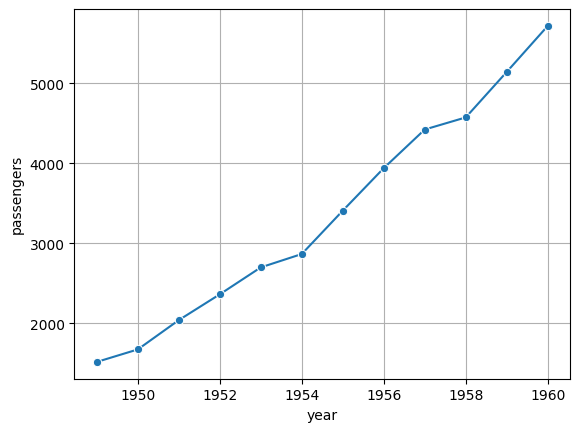

In [14]:
# Use: trends over the time.

# group the flight dataset yearwise

timeline_year = df.groupby("year")["passengers"].sum().reset_index()

sns.lineplot(x = timeline_year["year"], y = timeline_year["passengers"], marker = 'o')

# You can customize the seaborn chart using matplotlib

plt.grid()

# tips datasets

In [15]:
df = sns.load_dataset("tips")
df

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


<Axes: xlabel='total_bill', ylabel='tip'>

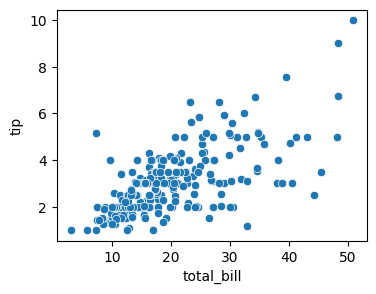

In [19]:
# Query: Find the relationship between total_bill and tips?
plt.figure(figsize = (4,3))
sns.scatterplot(x = "total_bill", y = "tip", data = df)

# Pairplot

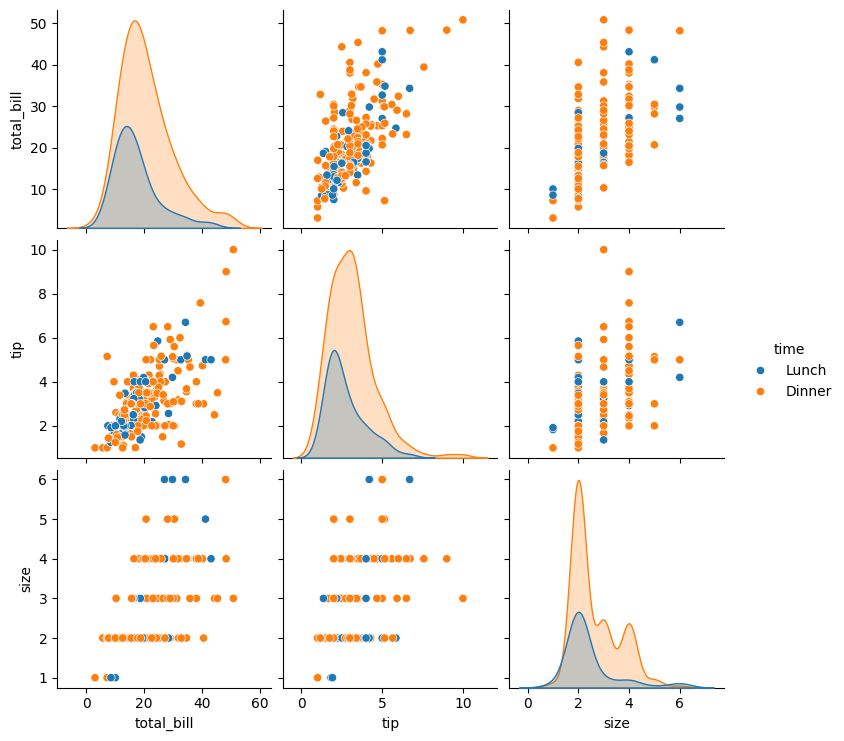

In [23]:
# Use: Pairplot shows the relationship between all the numerical variable together
# Hue parameter in pairplot, is used for categorize data
sns.pairplot(df, hue = "time")

# Heatmap 

In [32]:
# Heatmap is used to visulaization the correlation between two variable in colorful charts.
# df.corr() works on numerical data
corr_matrix = df.corr(numeric_only = True)
corr_matrix


,total_bill,tip,size
total_bill,1.000000,0.675734,0.598315
tip,0.675734,1.000000,0.489299
size,0.598315,0.489299,1.000000


<Axes: >

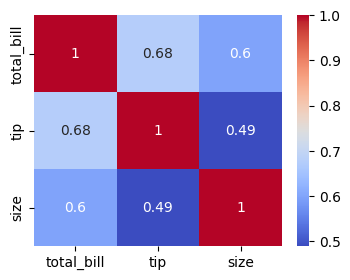

In [33]:
plt.figure(figsize = (4,3))
sns.heatmap(corr_matrix, annot= True,cmap = "coolwarm")

# Relationship between categorical columns

In [44]:
# uaing Pivot table: to find relationship between categorical variables.
# Heatmap make the colorful table for shwing pivot tables.
# categorical columns : sex, day, time, smoker.

pivot = df.pivot_table(index = ["day", "time"], columns = ["sex", "smoker"], aggfunc = "size", fill_value= 0)
pivot

sex         Male     Female    
smoker       Yes  No    Yes  No
day  time                      
Thur Lunch    10  20      7  24
     Dinner    0   0      0   1
Fri  Lunch     3   0      3   1
     Dinner    5   2      4   1
Sat  Dinner   27  32     15  13
Sun  Dinner   15  43      4  14

<Axes: xlabel='sex-smoker', ylabel='day-time'>

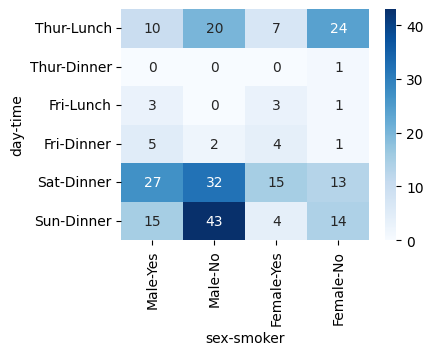

In [45]:
plt.figure(figsize = (4,3))
sns.heatmap(pivot,annot = True, cmap = "Blues")

# countplot : showing frequency of categorical data

<Axes: xlabel='smoker', ylabel='count'>

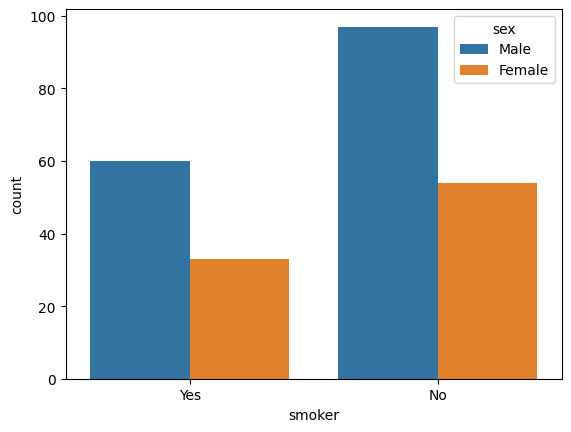

In [48]:
sns.countplot(data = df, x = "smoker", hue = "sex")